# Priorización de tareas: evaluación

Comparación del modelo Qwen3.5-4B original, LoRA y DoRA sobre los mismos casos. Las cifras provienen de las predicciones guardadas en Khipu; este notebook no vuelve a generar respuestas ni consume GPU.

> **Etapa inicial.** Este notebook conserva la ejecución preliminar con r=8 y alpha=16. La selección y las conclusiones finales de la ampliación están en **03_diseno_factorial.ipynb**, que contiene el factorial duplicado, la regresión, la comprobación fuera del dominio y la comparación actualizada con DoRA, rsLoRA y LoRA+.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / "results" / "COMPLETE.json").exists(), "Abra el notebook desde la carpeta del proyecto terminado."
metrics = json.loads((ROOT / "results" / "all_metrics.json").read_text(encoding="utf8"))
hardware = json.loads((ROOT / "results" / "hardware.json").read_text(encoding="utf8"))
summary = pd.read_csv(ROOT / "results" / "summary.csv")
names = {"base":"Base", "lora":"LoRA", "dora":"DoRA", "lora_replica":"LoRA, réplica"}
display(pd.DataFrame([{"GPU":hardware["gpu"], "Nodo":hardware["node"], "Job":hardware["job_id"], "PyTorch":hardware["torch"]}]))

,GPU,Nodo,Job,PyTorch
0,NVIDIA RTX A6000,ds001,58224,2.14.1+cu130


## Comparación con una tecnología más actual: DoRA

El enunciado pide contrastar el LoRA seleccionado con una tecnología posterior. **Este requisito se aborda con DoRA (Weight-Decomposed Low-Rank Adaptation), implementado en Hugging Face PEFT**. No es una propuesta teórica: se entrenó y evaluó en Khipu junto con LoRA.

LoRA aprende una actualización de bajo rango. DoRA separa la magnitud y la dirección de los pesos y aprende también parámetros de magnitud. Se activa en el mismo `LoraConfig` con `use_dora=True`; LoRA usa `False`. El código ejecutado está en `src/experiment.py` y los adaptadores en `adapters/lora/` y `adapters/dora/`.

La comparación principal usa semilla 42, rango 8, alpha 16, 32 actualizaciones y lote efectivo de 8. Conserva modelo original, particiones, prompt y hardware asignado. Cada método parte de una carga independiente. **El LoRA de referencia es el seleccionado entre las ejecuciones disponibles por F1 de validación**: 0.776 frente a 0.683 de su réplica. DoRA también obtuvo 0.776 en validación. La prueba se usa para informar resultados, no para seleccionar el adaptador.

Se comparan F1 macro, formato, errores críticos, robustez, tiempo, memoria y costo simulado. La conclusión se limita a esta configuración y presupuesto. Fuente del método: [DoRA, Liu et al. (2024)](https://arxiv.org/abs/2402.09353) y [documentación de PEFT](https://huggingface.co/docs/peft/en/package_reference/lora).

## 1. Diseño de evaluación

F1 macro es la métrica principal porque asigna el mismo peso a las cuatro prioridades. También se mide recuperación de tareas críticas, error ordinal y coincidencia exacta de los cuatro campos. Una respuesta con JSON o esquema inválido cuenta como error; no se intenta repararla.

Los hiperparámetros se fijan antes de la evaluación. La prueba tiene 64 casos separados por familia de tarea; el conjunto adicional tiene 16. El indicador de clase mayoritaria sirve como referencia mínima.

In [2]:
from sklearn.metrics import f1_score, accuracy_score
test = [json.loads(s) for s in (ROOT / "data" / "test.jsonl").read_text(encoding="utf8").splitlines()]
y = [json.loads(r["output"])["prioridad"] for r in test]
display(pd.DataFrame([{"Referencia":"Siempre media", "Accuracy":accuracy_score(y,["media"]*len(y)), "F1 macro":f1_score(y,["media"]*len(y),average="macro")}]))
view=summary[["label","macro_f1","ci_low","ci_high","schema_rate","exact_match","critical_recall","ordinal_mae"]].copy()
for col in ["schema_rate","exact_match","critical_recall"]:
    view[col] *= 100
display(view.rename(columns={"label":"Modelo","macro_f1":"F1 macro","ci_low":"IC inf.","ci_high":"IC sup.","schema_rate":"Esquema (%)","exact_match":"Total correcto (%)","critical_recall":"Rec. crítica (%)","ordinal_mae":"Error ordinal"}).round(3))
display(summary[["label","priority_only_f1","duplicate_key_cases"]].rename(columns={"label":"Modelo","priority_only_f1":"F1 solo prioridad","duplicate_key_cases":"Casos con claves repetidas"}).round(3))

,Referencia,Accuracy,F1 macro
0,Siempre media,0.25,0.1


,Modelo,F1 macro,IC inf.,IC sup.,Esquema (%),Total correcto (%),Rec. crítica (%),Error ordinal
0,Base,0.760,0.668,0.849,90.625,53.125,87.5,0.453
1,LoRA,0.876,0.799,0.938,100.000,78.125,87.5,0.141
2,DoRA,0.876,0.799,0.938,100.000,78.125,87.5,0.141
3,"LoRA, réplica",0.830,0.735,0.908,100.000,71.875,87.5,0.188


,Modelo,F1 solo prioridad,Casos con claves repetidas
0,Base,0.750,5
1,LoRA,0.876,0
2,DoRA,0.876,0
3,"LoRA, réplica",0.830,0


## 2. Desempeño y formato

El intervalo del gráfico se obtiene con 1 000 remuestreos estratificados de los casos de prueba. Describe incertidumbre por los ejemplos disponibles; no mide variación entre entrenamientos. Los cuatro modelos utilizan los mismos índices en cada remuestreo.

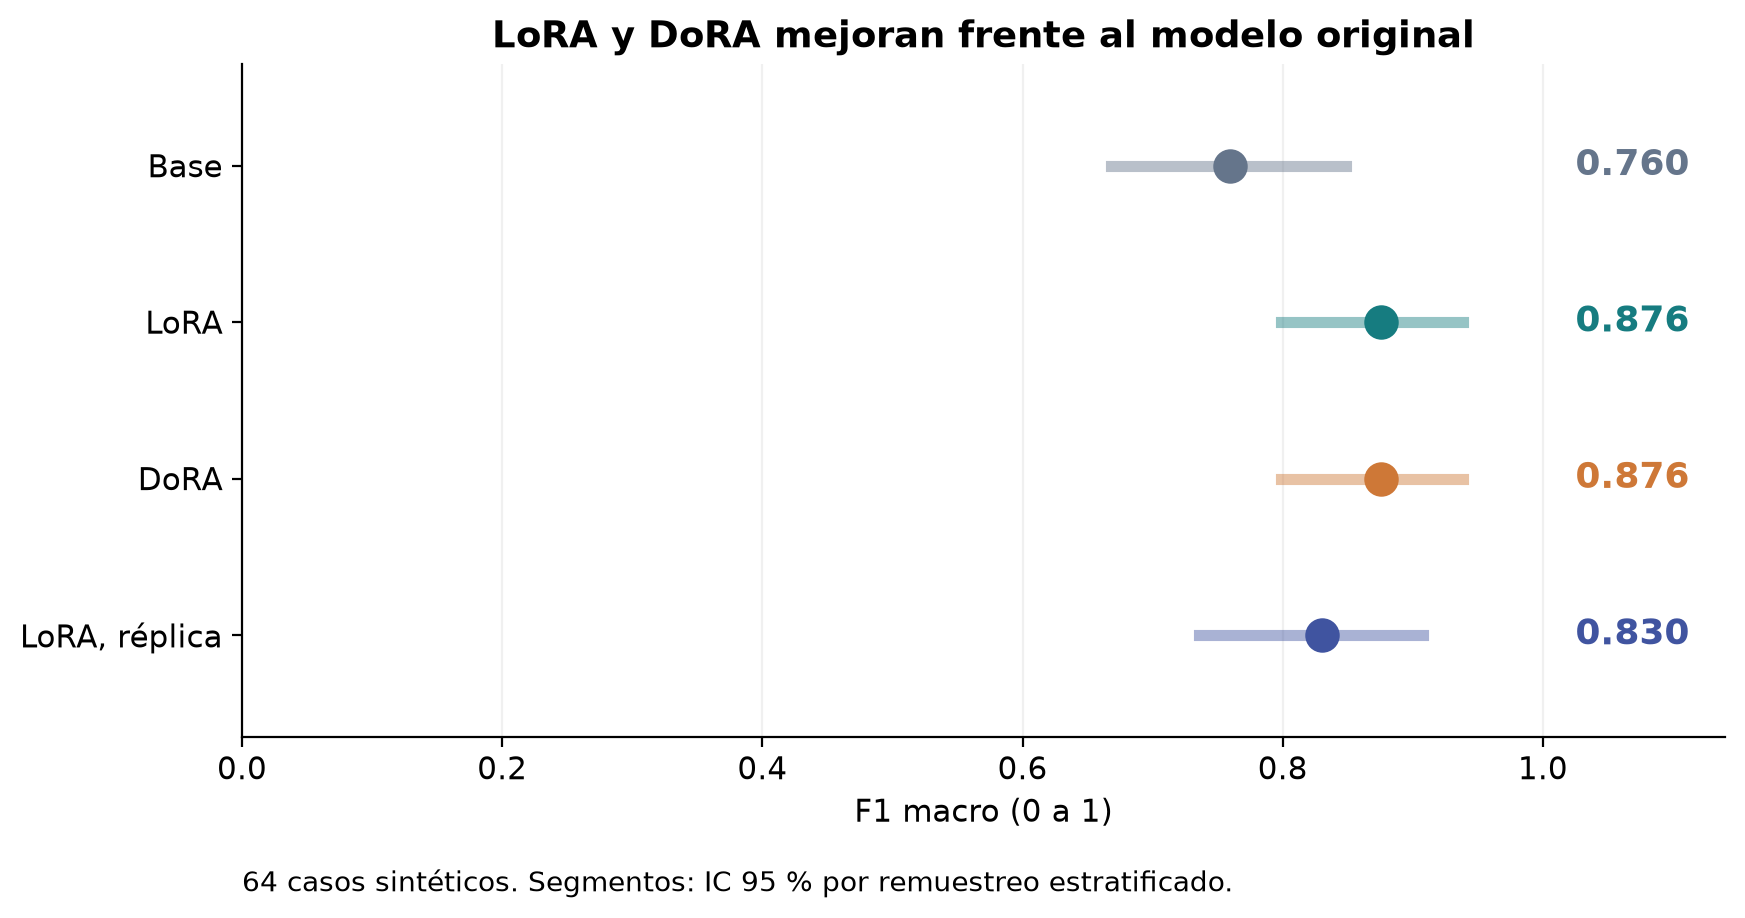

LoRA cambia el F1 macro en **+11.61 puntos porcentuales** frente al modelo base en esta prueba.

,Límite inferior,Límite superior
lora,0.038,0.203
dora,0.038,0.203
lora_replica,-0.018,0.160


In [3]:
display(Image(filename=str(ROOT / "figures" / "desempeno.png")))
analysis=json.loads((ROOT / "results" / "analysis.json").read_text(encoding="utf8"))
delta=analysis["max_delta"]
display(Markdown(f"LoRA cambia el F1 macro en **{100*delta:+.2f} puntos porcentuales** frente al modelo base en esta prueba."))
display(pd.DataFrame(analysis["paired_f1_difference_ci"]).T.rename(columns={0:"Límite inferior",1:"Límite superior"}).round(3))

Los intervalos de diferencias utilizan un remuestreo pareado. Un intervalo que incluya cero no aporta evidencia clara de una diferencia en este conjunto. Con pocos casos y pocas semillas, las conclusiones se limitan al ejercicio.

Como diagnóstico adicional se calcula F1 solo sobre el campo `prioridad`, sin exigir la validez de los demás campos. Se rechaza una prioridad repetida o fuera de las cuatro clases. Este diagnóstico ayuda a separar errores de decisión y de formato; no sustituye la métrica estricta ni repara las respuestas.

## 3. Errores y casos difíciles

La matriz corresponde a la condición con mayor F1 macro en validación entre base, LoRA y DoRA. Esa elección no usa la prueba. La columna «inválida» conserva los fallos de formato para que no desaparezcan de la evaluación.

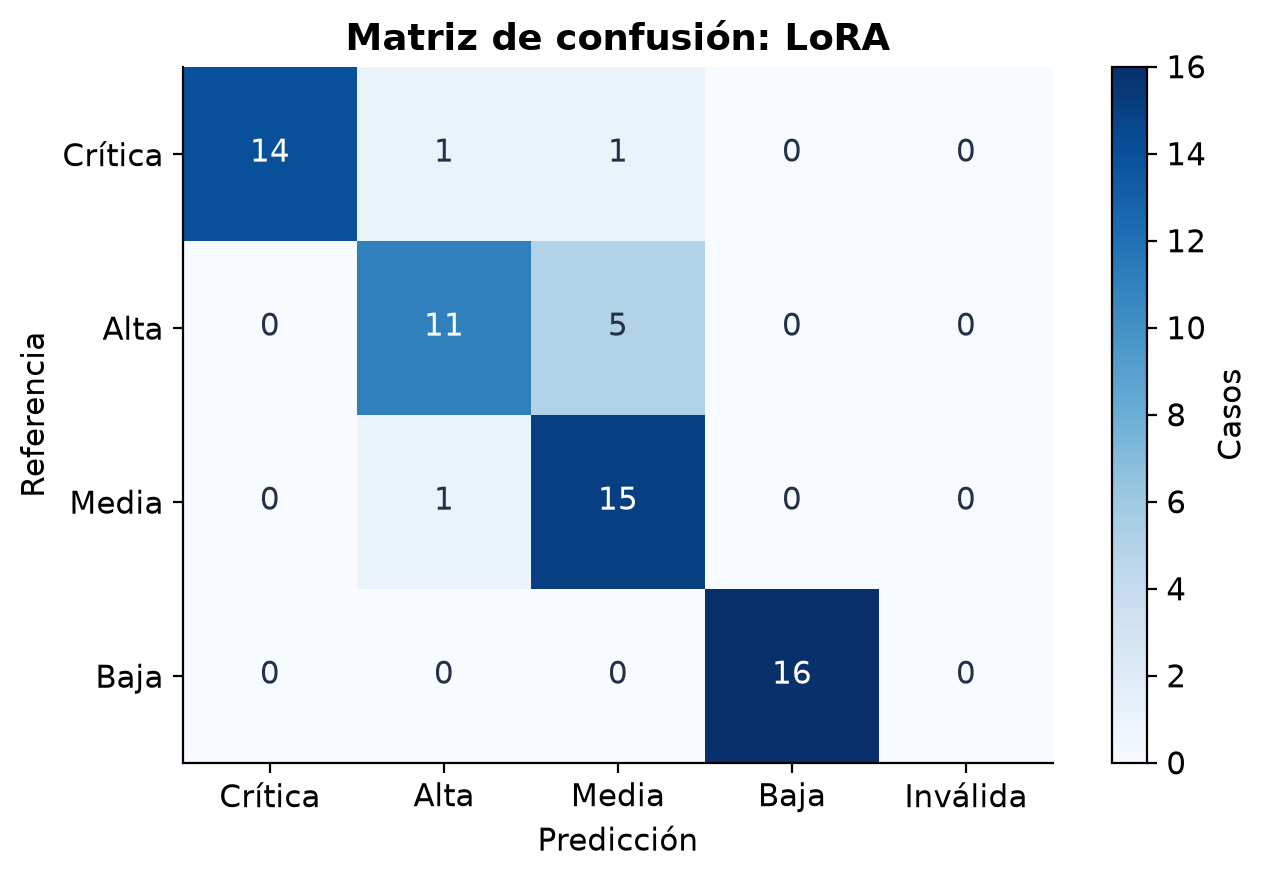

,Modelo,F1 casos difíciles,Rec. crítica (0-1),Error ordinal
0,Base,0.750,0.875,0.453
1,LoRA,0.937,0.875,0.141
2,DoRA,0.879,0.875,0.141
3,"LoRA, réplica",0.750,0.875,0.188


method,base,dora,lora,lora_replica
priority,,,,
alta,0.750,0.688,0.688,0.562
baja,0.938,1.000,1.000,0.875
critica,0.875,0.875,0.875,0.875
media,0.375,0.938,0.938,1.000


In [4]:
display(Image(filename=str(ROOT / "figures" / "confusion.png")))
display(summary[["label","stress_f1","critical_recall","ordinal_mae"]].rename(columns={"label":"Modelo","stress_f1":"F1 casos difíciles","critical_recall":"Rec. crítica (0-1)","ordinal_mae":"Error ordinal"}).round(3))
slices=pd.read_csv(ROOT / "results" / "slices.csv")
display(slices[slices["split"]=="test"].pivot(index="priority",columns="method",values="recall").round(3))

In [5]:
errors=json.loads((ROOT / "results" / "error_examples.json").read_text(encoding="utf8"))
for name, cases in errors.items():
    display(Markdown("### " + names[name]))
    if not cases:
        print("No se observaron errores de coincidencia exacta en la prueba.")
    for row in cases[:1]:
        print(row["input"])
        print("Referencia:", row["truth"])
        print("Respuesta:", row["raw"])
        print()

### Base

Necesitamos recuperar la plataforma de becas; tenemos 49 horas de plazo. El impacto se considera medio y alcanza a 400 personas. De este trabajo dependen 0 tareas. Falta una autorización previa; la tarea está bloqueada. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Referencia: {'prioridad': 'critica', 'escalar': True, 'bloqueada': True, 'criterio': 'impacto'}
Respuesta: {"prioridad":"alta","escalar":false,"bloqueada":true,"criterio":"impacto"}



### LoRA

Necesitamos recuperar la plataforma de becas; tenemos 49 horas de plazo. El impacto se considera medio y alcanza a 400 personas. De este trabajo dependen 0 tareas. Falta una autorización previa; la tarea está bloqueada. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Referencia: {'prioridad': 'critica', 'escalar': True, 'bloqueada': True, 'criterio': 'impacto'}
Respuesta: {"prioridad": "media", "escalar": false, "bloqueada": true, "criterio": "impacto"}



### DoRA

Necesitamos recuperar la plataforma de becas; tenemos 49 horas de plazo. El impacto se considera medio y alcanza a 400 personas. De este trabajo dependen 0 tareas. Falta una autorización previa; la tarea está bloqueada. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Referencia: {'prioridad': 'critica', 'escalar': True, 'bloqueada': True, 'criterio': 'impacto'}
Respuesta: {"prioridad": "media", "escalar": false, "bloqueada": true, "criterio": "impacto"}



### LoRA, réplica

Necesitamos recuperar la plataforma de becas; tenemos 49 horas de plazo. El impacto se considera medio y alcanza a 400 personas. De este trabajo dependen 0 tareas. Falta una autorización previa; la tarea está bloqueada. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Referencia: {'prioridad': 'critica', 'escalar': True, 'bloqueada': True, 'criterio': 'impacto'}
Respuesta: {"prioridad": "media", "escalar": false, "bloqueada": true, "criterio": "impacto"}



El conjunto difícil agrega expresiones de presión, cambios de cortesía e instrucciones contradictorias sin cambiar los hechos que determinan la prioridad. Su tamaño pequeño permite detectar fallos concretos; no alcanza para caracterizar toda la robustez del modelo.

## 4. Recursos, latencia y costo simulado

La latencia se mide por solicitud, con lote de uno, sincronización CUDA y un calentamiento excluido. Los adaptadores se evalúan sin fusionar con los pesos base. Todas las condiciones usan el mismo nodo RTX A6000 y la misma reserva de shards. Otros usuarios comparten la GPU, por lo que los tiempos pueden variar por carga externa.

Para comparar costos se supone **USD 1 por hora del recurso GPU asignado**. Es un escenario hipotético; Khipu no ha cobrado ese importe. El cálculo mostrado incluye solo entrenamiento.

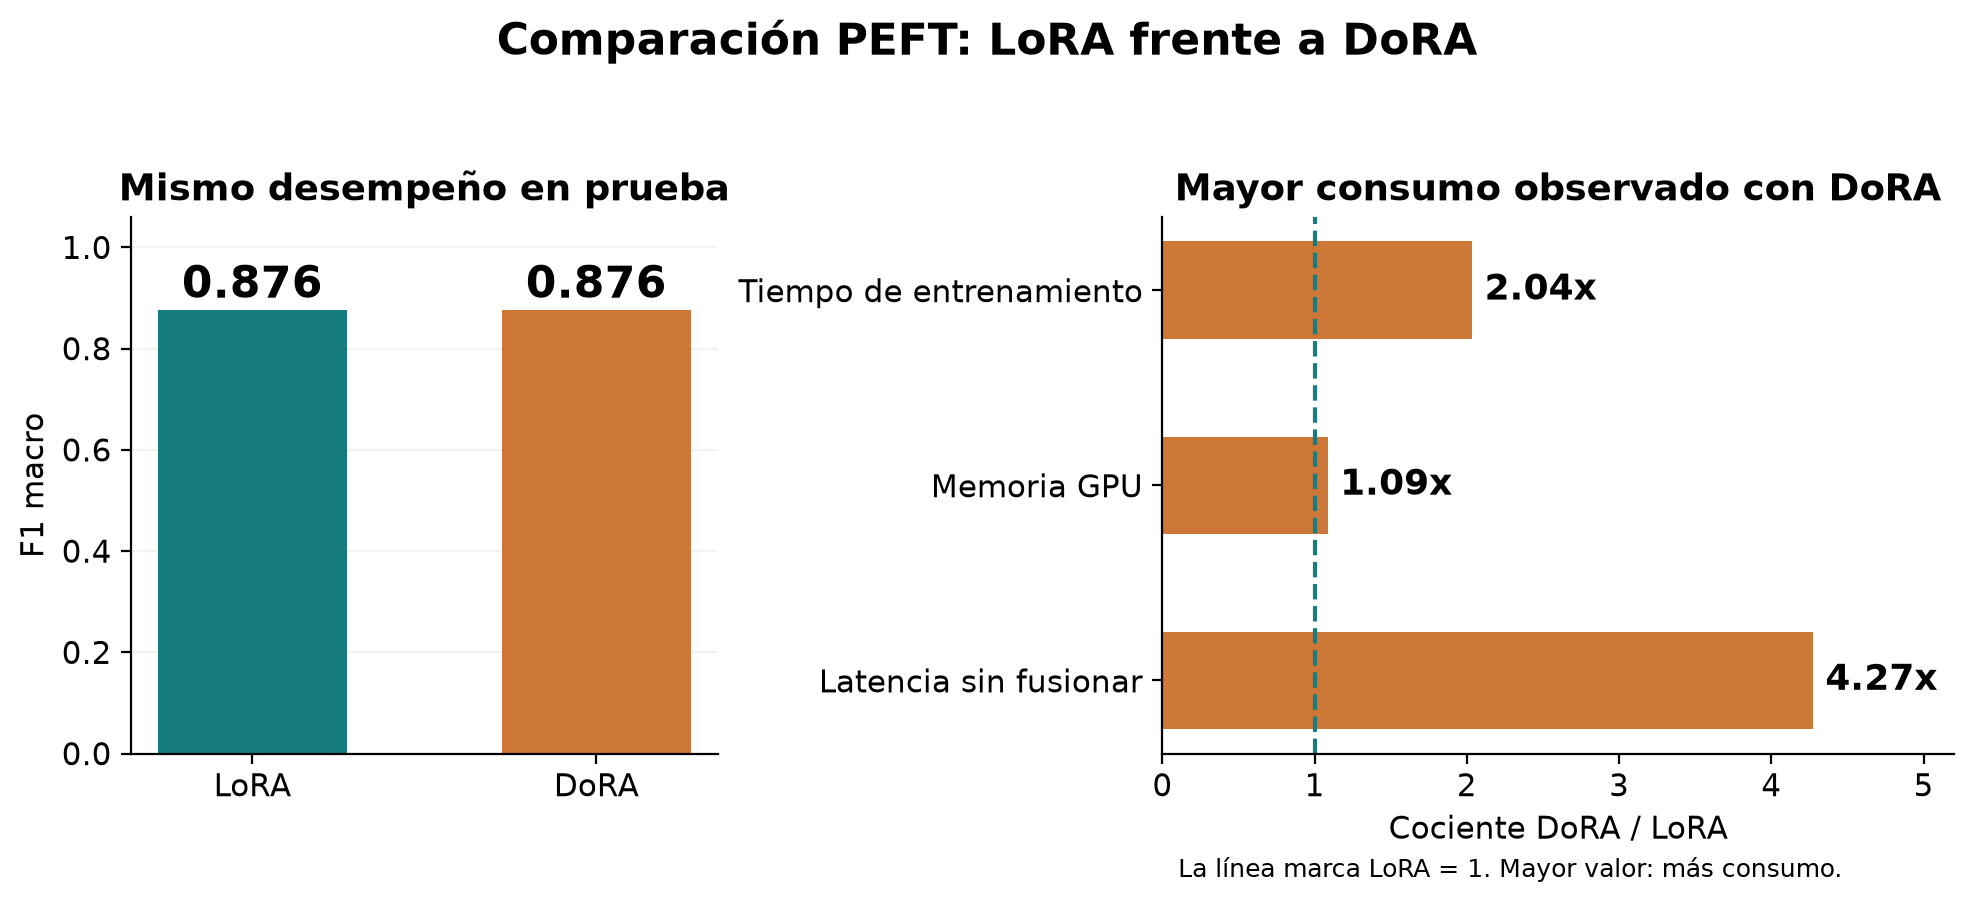

**Decisión:** LoRA y DoRA empatan en F1 macro (0.876), esquema válido (100 %) y recuperación crítica (87.5 %). DoRA requiere 2.04 veces el tiempo de entrenamiento y 1.09 veces la memoria. Su latencia observada es 4.27 veces mayor con adaptadores sin fusionar. Se recomienda LoRA para este prototipo; el resultado no demuestra superioridad general frente a DoRA.

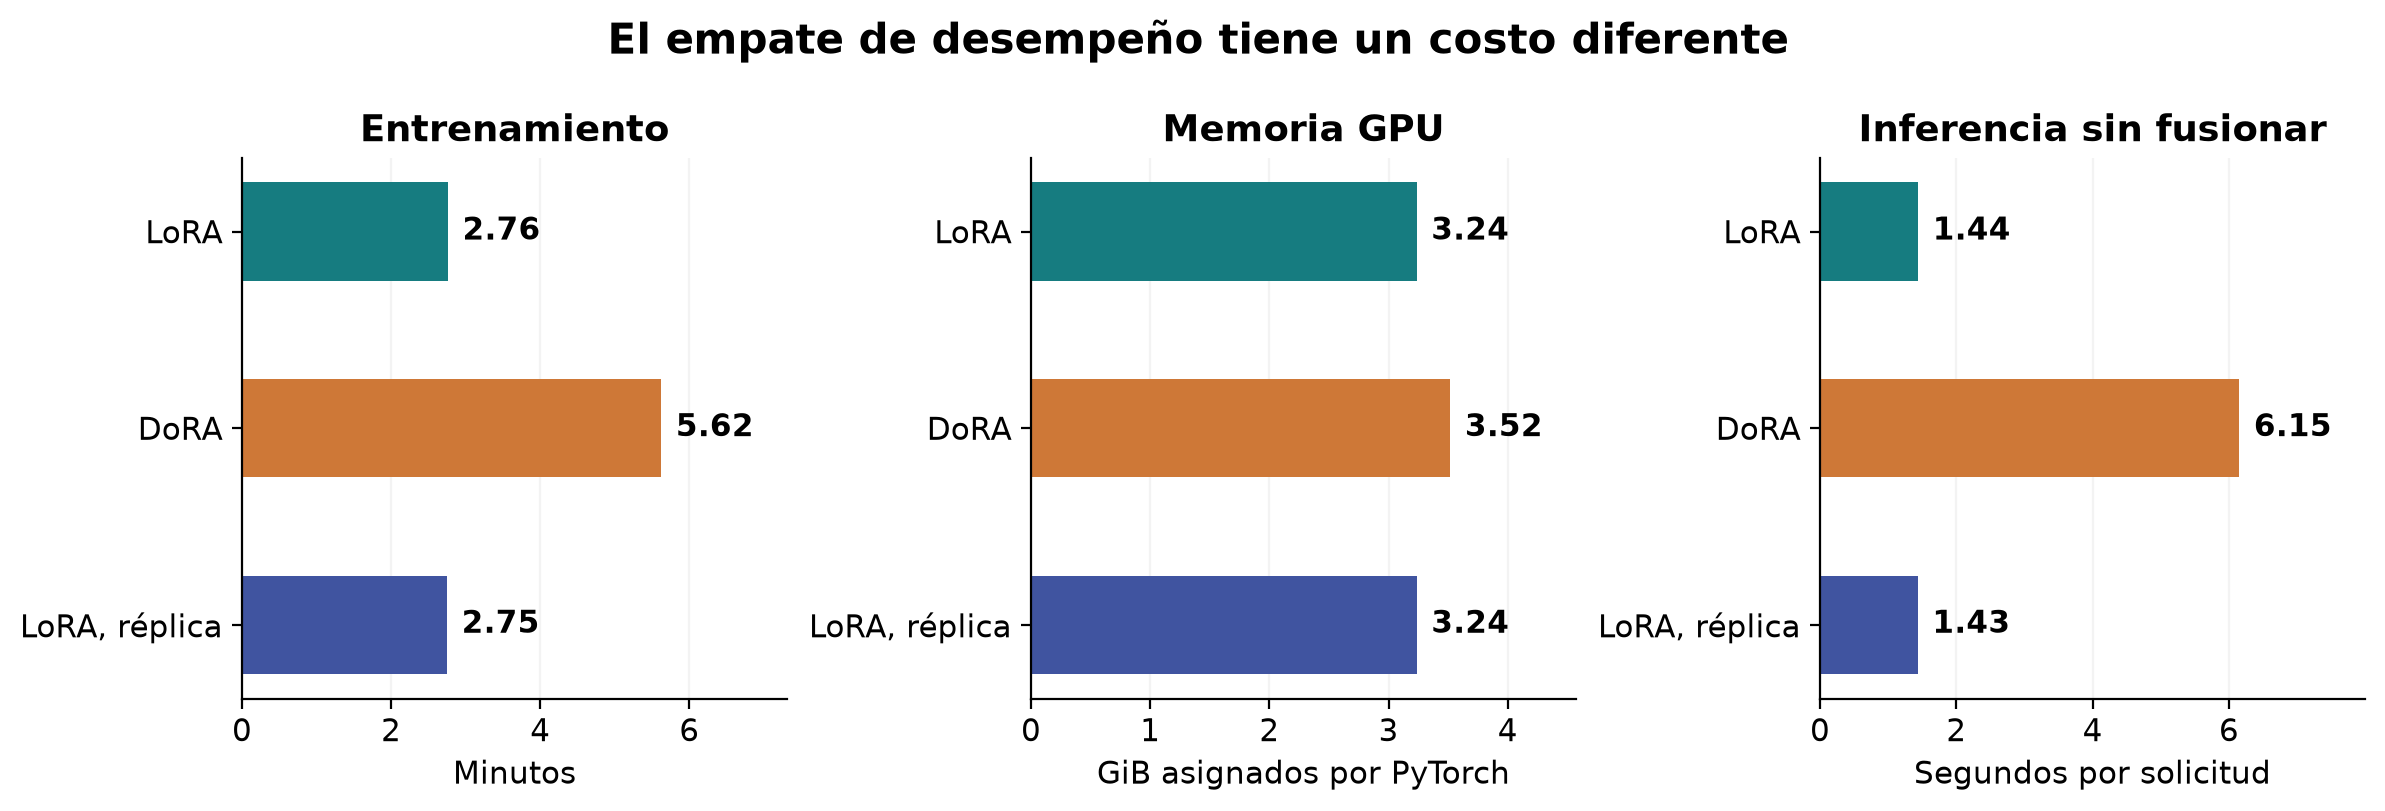

,Modelo,Entrenamiento (min),VRAM (GiB),USD simulados
0,Base,0.0000,0.0000,0.0000
1,LoRA,2.7617,3.2353,0.0460
2,DoRA,5.6239,3.5178,0.0937
3,"LoRA, réplica",2.7502,3.2358,0.0458


,Modelo,Latencia (s),Tokens por respuesta,Tokens/s
0,Base,1.141,29.797,26.113
1,LoRA,1.439,31.469,21.868
2,DoRA,6.151,31.469,5.116
3,"LoRA, réplica",1.433,31.438,21.931


**Réplica de LoRA:** F1 macro de 0.876 con semilla 42 y 0.830 con semilla 43. La diferencia entre ambas ejecuciones es 0.045.

In [6]:
display(Image(filename=str(ROOT / "figures" / "comparacion_peft.png")))
display(Markdown("**Decisión:** LoRA y DoRA empatan en F1 macro (0.876), esquema válido (100 %) y recuperación crítica (87.5 %). DoRA requiere 2.04 veces el tiempo de entrenamiento y 1.09 veces la memoria. Su latencia observada es 4.27 veces mayor con adaptadores sin fusionar. Se recomienda LoRA para este prototipo; el resultado no demuestra superioridad general frente a DoRA."))
display(Image(filename=str(ROOT / "figures" / "recursos.png")))
display(summary[["label","train_min","train_vram_gb","train_cost_usd"]].rename(columns={"label":"Modelo","train_min":"Entrenamiento (min)","train_vram_gb":"VRAM (GiB)","train_cost_usd":"USD simulados"}).round(4))
display(summary[["label","latency_s","mean_generated_tokens","generated_tokens_per_second"]].rename(columns={"label":"Modelo","latency_s":"Latencia (s)","mean_generated_tokens":"Tokens por respuesta","generated_tokens_per_second":"Tokens/s"}).round(3))
if "lora_replica" in metrics:
    a=metrics["lora"]["test"]["macro_f1"]
    b=metrics["lora_replica"]["test"]["macro_f1"]
    display(Markdown(f"**Réplica de LoRA:** F1 macro de {a:.3f} con semilla 42 y {b:.3f} con semilla 43. La diferencia entre ambas ejecuciones es {abs(a-b):.3f}."))

## 5. Conclusiones y límites

La elección debe considerar acierto, tratamiento de tareas críticas y costo computacional. Ajustar el modelo solo aporta valor si mejora esos resultados en datos nuevos; un JSON válido no garantiza una prioridad correcta.

Los datos son sintéticos y expresan los criterios con bastante claridad. Si esos criterios ya estuvieran disponibles como campos estructurados, una función de reglas sería más simple y auditable. El interés del LLM está en interpretar solicitudes libres; comprobar ese uso requiere ejemplos reales y revisión humana independiente.

La réplica permite observar sensibilidad a una segunda semilla, pero no establece una distribución completa de resultados. El informe y la presentación recogen la comparación numérica y la recomendación correspondiente.

**Fuentes:** material del docente en `originales/`; [Qwen](https://huggingface.co/Qwen/Qwen3.5-4B), [PEFT](https://huggingface.co/docs/peft/en/package_reference/lora), [Khipu](https://docs.khipu.utec.edu.pe/).

## Resultado final de la ampliación factorial

La comparación anterior corresponde a la configuración inicial. El siguiente resumen usa la elección obtenida con las doce condiciones del factorial y sus comprobaciones adicionales.

In [7]:
factorial_root=ROOT/'factorial'
selection_final=json.loads((factorial_root/'results/selection.json').read_text(encoding='utf8'))['selected']
final_cells=pd.read_csv(factorial_root/'results/cells.csv')
display(final_cells[(final_cells['rank']==selection_final['rank']) & (final_cells.alpha==selection_final['alpha'])].round(4))
display(Markdown((factorial_root/'conclusion.md').read_text(encoding='utf8')))

,method,rank,alpha,n,validation_f1,validation_sd,test_f1,test_sd,stress_f1,schema,critical_recall,train_seconds,train_vram_gib,latency_s,cost_usd,pareto
0,lora,1,32,2,0.8284,0.0673,0.8915,0.0185,0.8468,1.0,0.9062,224.5388,3.1963,1.9743,0.0624,True
8,dora,1,32,2,0.8356,0.0571,0.8896,0.0005,0.9365,1.0,0.9062,652.6900,3.4763,12.3553,0.1813,NaN
9,rslora,1,32,2,0.8186,0.0297,0.8830,0.0103,0.8468,1.0,0.8750,323.5572,3.1873,2.0899,0.0899,NaN
11,loraplus,1,32,2,0.7041,0.1304,0.7218,0.0393,0.5239,1.0,0.9375,316.3802,3.1963,2.2146,0.0879,NaN


**Configuración recomendada:** LoRA con r=1 y alpha=32, elegido por validación según la tolerancia práctica fijada antes del experimento. Su F1 medio de validación es 0.828 y el de prueba 0.891.

Al pasar de r=1 a r=2 con alpha=32, la diferencia media en validación fue -0.022. Su límite superior unilateral del 95 % fue 0.017, menor que el margen práctico de 0.02. En este tramo, con los casos y semillas medidos, los resultados no justifican aumentar el rango para buscar una ganancia de 0.02 o más.

El máximo previsto por la superficie fue r=1, alpha=32, con F1 0.807. La comprobación real con dos semillas obtuvo 0.828. El modelo de regresión orienta la búsqueda, pero no reemplaza las mediciones.

En los 128 casos nuevos, el F1 fue 0.794 para base, 0.835 para LoRA y 0.838 para DoRA, promediando las dos réplicas de los adaptadores. DoRA necesitó 2.91 veces el tiempo de entrenamiento y 1.09 veces la VRAM de LoRA. La diferencia DoRA menos LoRA en confirmación fue +0.004, con intervalo del 95 % [-0.017, +0.027].

El óptimo y la frontera corresponden a la política sintética, 256 ejemplos de entrenamiento y 32 actualizaciones. No son límites universales de LoRA. Dos semillas y una GPU compartida restringen la precisión de las conclusiones.

**Comparación ampliada:** rsLoRA obtiene F1 0.855 y LoRA+ 0.709 en los 128 casos nuevos. Entre los métodos con rango y alpha compartidos, la mayor media de validación corresponde a DoRA. Las tasas de LoRA+ se mantienen en razón B/A=16 durante los 32 pasos. Estos métodos comparten la configuración seleccionada para LoRA; no se buscaron sus óptimos por separado. Los intervalos de las tres comparaciones son exploratorios y no están ajustados por multiplicidad.

Con r=1, las escalas alpha/r y alpha/sqrt(r) coinciden. Por eso las diferencias observadas entre LoRA y rsLoRA en ese rango no se atribuyen al reescalamiento. Se fijaron las semillas, pero no se forzó el uso exclusivo de kernels deterministas de CUDA. Se agregó una comparación duplicada de rsLoRA con r=32 frente al LoRA correspondiente del factorial, donde las escalas sí difieren. Sus resultados se conservan en rslora_control_summary.csv y no cambian la configuración compartida ni la selección con confirmación.

La mayor media descriptiva en la confirmación corresponde a rsLoRA (0.855), mientras que validación había elegido DoRA. No se cambia la selección usando este conjunto nuevo. El cambio de orden muestra la incertidumbre de comparar métodos con particiones pequeñas y dos semillas.